# Análisis de tendencias NASA desde Python — vía API (sin Earth Engine en el cliente)

Este notebook reproduce, **solo con la API REST y el SDK oficial**, lo que la plataforma web hace al pulsar *Analizar*:
elegir variable NASA, territorio, periodo, estimador e intervalo de confianza, y obtener **qué cambia, dónde, cuánto y
si el cambio es estadísticamente distinguible de cero**.

* No necesita credenciales de Google Earth Engine: el backend procesa los datos NASA.
* No usa notebooks ni archivos de estudios anteriores.
* Variables de entorno: `EARTH_TREND_API_URL` (p. ej. `http://localhost:8000/api/v1`) y, si el servidor lo exige,
  `EARTH_TREND_API_TOKEN`.

> **Cómo leer los resultados.** Un IC del 95 % es una propiedad del *procedimiento* bajo sus supuestos, no "95 % de
> probabilidad de que el valor esté dentro". Un p-valor alto **no** prueba ausencia de cambio: indica que los datos no
> permiten distinguirlo de cero con ese método.

In [1]:
# pip install -e packages/python-sdk[plot]   (desde la raíz del repositorio)
import os
import pandas as pd
from earth_trend_client import EarthTrendClient, EarthTrendAPIError

os.environ.setdefault("EARTH_TREND_API_URL", "http://localhost:8000/api/v1")
client = EarthTrendClient(timeout=900)
client.health()

{'status': 'ok',
 'version': '0.1.0',
 'algorithm_version': 'trend_core/0.1.0',
 'earth_engine_configured': True,
 'earth_engine_auth_mode': 'service_account'}

## 1. ¿Qué variables NASA hay? (catálogo)

In [2]:
variables = pd.DataFrame(client.catalog.variables())
variables[["dataset_id", "variable_id", "physical_quantity", "unit_display", "temporal_aggregations"]]

,dataset_id,variable_id,physical_quantity,unit_display,temporal_aggregations
0,nasa-gpm-imerg-monthly-v07,precipitation_mm_month,precipitación total,mm,"[total, mean]"
1,nasa-gldas-noah-v21-3h,soil_moisture_0_10cm_kgm2,humedad del suelo 0–10 cm (modelo),kg/m²,[mean]
2,nasa-gldas-noah-v21-3h,air_temperature_c,temperatura del aire (forzante del modelo),°C,[mean]
3,nasa-merra2-slv,air_temperature_2m_c,temperatura del aire a 2 m (reanálisis),°C,[mean]
4,nasa-merra2-slv,total_precipitable_water_kgm2,vapor de agua precipitable total,kg/m²,[mean]
5,nasa-merra2-slv,wind_u_10m_ms,viento zonal a 10 m,m/s,[mean]
6,nasa-merra2-slv,wind_v_10m_ms,viento meridional a 10 m,m/s,[mean]
7,nasa-modis-mod13q1-061,ndvi,índice de vegetación de diferencia normalizada,adimensional,[mean]
8,nasa-modis-aqua-sst-l3smi,sst_c,temperatura superficial del mar,°C,[mean]


In [3]:
datasets = pd.DataFrame(client.catalog.datasets())
datasets[["dataset_id", "ee_collection_id", "nominal_resolution", "temporal_coverage_start", "native_granularity"]]

,dataset_id,ee_collection_id,nominal_resolution,temporal_coverage_start,native_granularity
0,nasa-gpm-imerg-monthly-v07,NASA/GPM_L3/IMERG_MONTHLY_V07,0.1° (~11 km en el ecuador),1998-01-01,month
1,nasa-gldas-noah-v21-3h,NASA/GLDAS/V021/NOAH/G025/T3H,0.25° (~28 km),2000-01-01,3h
2,nasa-merra2-slv,NASA/GSFC/MERRA/slv/2,0.5° × 0.625° (~55 × 69 km),1980-01-01,1h
3,nasa-modis-mod13q1-061,MODIS/061/MOD13Q1,250 m,2000-02-18,16d
4,nasa-modis-aqua-sst-l3smi,NASA/OCEANDATA/MODIS-Aqua/L3SMI,4 km,2002-07-04,1d


## 2. ¿Dónde? (territorio con fronteras versionadas)

Para Perú se usa por defecto la cartografía oficial del IGN (ADM1–ADM3 con UBIGEO); para el resto del mundo,
geoBoundaries. Cada territorio tiene un `geo_id` estable que incluye la versión de la frontera.

In [4]:
hits = client.geographies.search("trujillo", country="PER")
pd.DataFrame(hits)[["geo_id", "name", "admin_level", "path", "area_km2", "boundary_set_id"]]

,geo_id,name,admin_level,path,area_km2,boundary_set_id
0,pe-ign2020:1301,Trujillo,ADM2,"[Perú, La Libertad]",1775.577,pe-ign-cod-ab-2020
1,pe-ign2020:130101,Trujillo,ADM3,"[Perú, La Libertad, Trujillo]",38.222,pe-ign-cod-ab-2020


In [5]:
provincia = next(h for h in hits if h["admin_level"] == "ADM2")
provincia["geo_id"], provincia["area_km2"]

('pe-ign2020:1301', 1775.577)

## 3. ¿Cuánto cambia y es significativo? — precipitación anual IMERG 2003–2024

Totales anuales (los años incompletos se excluyen, no se rellenan). Estimador Theil–Sen (robusto a extremos), su
propio IC y prueba de Mann–Kendall.

In [6]:
base = {
    "data": {"dataset_id": "nasa-gpm-imerg-monthly-v07", "variable_id": "precipitation_mm_month"},
    "geography": {"geo_ids": [provincia["geo_id"]]},
    "time": {"start": "2003-01-01", "end_exclusive": "2025-01-01", "granularity": "year",
             "temporal_aggregation": "total"},
}
spec_sen = base | {"statistics": {"estimator": "theil_sen", "interval_method": "theil_sen_analytic",
                                  "significance_test": "mann_kendall"}}
run_sen = client.analyses.run(spec_sen, idempotency_key="nb01-imerg-anual-sen")
st = client.analyses.statistics(run_sen.id)
print(run_sen.id)
print(f"{st.estimate:.2f} {st.estimate_unit} · {st.confidence_interval} · {st.hypothesis_test} · N={st.n_observations}")
for w in st.warnings:
    print("aviso:", w)

run_faa92e2c5526d07ea622
-15.85 mm/decade · IC 95% [-37.15, 24.08] (theil_sen_analytic) · mann_kendall: p=0.398 · N=22


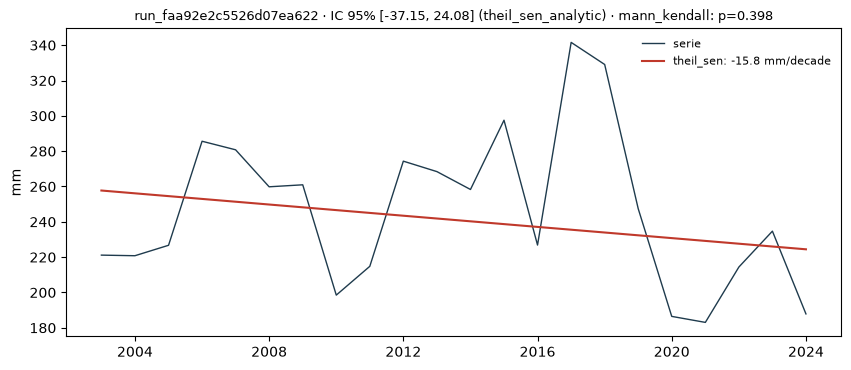

In [7]:
ax = client.analyses.plot(run_sen.id)

## 4. ¿Resiste el resultado a un cambio de método?

Misma serie, otros procedimientos. La extracción NASA se reutiliza desde caché: solo cambia la estadística.

In [8]:
variantes = {
    "Theil–Sen + IC analítico + MK": spec_sen["statistics"],
    "OLS + IC HAC (Newey–West) + t-HAC": {"estimator": "ols", "interval_method": "hac_newey_west",
                                          "significance_test": "ols_hac_t"},
    "Theil–Sen + bootstrap por bloques (b=3)": {"estimator": "theil_sen", "interval_method": "moving_block_bootstrap",
                                                "significance_test": "mann_kendall", "block_length": 3, "seed": 2026},
    "Theil–Sen + IC 90 %": {"estimator": "theil_sen", "interval_method": "theil_sen_analytic",
                            "significance_test": "mann_kendall", "confidence_level": 0.90},
}
filas = []
for nombre, stats in variantes.items():
    r = client.analyses.run(base | {"statistics": stats})
    s = client.analyses.statistics(r.id)
    filas.append({"método": nombre, "pendiente": s.estimate, "unidad": s.estimate_unit,
                  "IC_inf": s.confidence_interval.lower, "IC_sup": s.confidence_interval.upper,
                  "nivel": s.confidence_interval.level, "p": s.hypothesis_test.p_value,
                  "extracción_en_caché": r.raw["extraction_cache_hit"], "run_id": r.id})
pd.DataFrame(filas).round(3)

,método,pendiente,unidad,IC_inf,IC_sup,nivel,p,extracción_en_caché,run_id
0,Theil–Sen + IC analítico + MK,-15.846,mm/decade,-37.154,24.077,0.95,0.398,False,run_faa92e2c5526d07ea622
1,OLS + IC HAC (Newey–West) + t-HAC,-10.218,mm/decade,-42.114,21.677,0.95,0.530,True,run_d984efd2e4d56f4c43f7
2,Theil–Sen + bootstrap por bloques (b=3),-15.846,mm/decade,-50.272,16.134,0.95,0.398,True,run_6422a0c48e4b9871daf7
3,Theil–Sen + IC 90 %,-15.846,mm/decade,-33.914,16.592,0.90,0.398,True,run_6e595f3fc6c23ae88949


## 5. Serie mensual sin estacionalidad (anomalías respecto a la climatología de cada mes)

Enero se compara con eneros, febrero con febreros, etc. El IC usa bootstrap por bloques de 12 meses para respetar la
dependencia temporal.

-0.6141612082053056 · mm/decade · IC 95% [-1.893, 0.6513] (moving_block_bootstrap) · mann_kendall: p=0.3


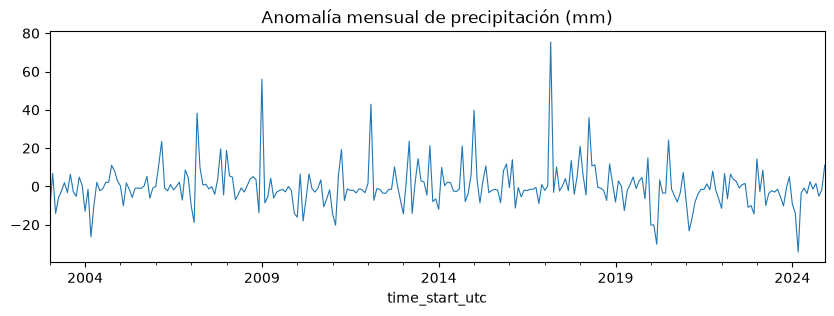

In [9]:
spec_anom = base | {
    "time": {"start": "2003-01-01", "end_exclusive": "2025-01-01", "granularity": "month"},
    "transforms": {"seasonality": "monthly_anomaly"},
    "statistics": {"estimator": "theil_sen", "interval_method": "moving_block_bootstrap",
                   "significance_test": "mann_kendall", "block_length": 12, "resamples": 1000, "seed": 2026},
}
run_anom = client.analyses.run(spec_anom)
st_anom = client.analyses.statistics(run_anom.id)
serie = client.analyses.series_dataframe(run_anom.id)
print(st_anom.estimate, st_anom.estimate_unit, st_anom.confidence_interval, st_anom.hypothesis_test, sep=" · ")
serie.set_index("time_start_utc")["value"].plot(figsize=(10, 3), lw=0.8, title="Anomalía mensual de precipitación (mm)");

## 6. Otra variable: vegetación (MODIS NDVI, 250 m, máscara de calidad)

In [10]:
spec_ndvi = {
    "data": {"dataset_id": "nasa-modis-mod13q1-061", "variable_id": "ndvi"},
    "geography": {"geo_ids": [provincia["geo_id"]]},
    "time": {"start": "2003-01-01", "end_exclusive": "2025-01-01", "granularity": "year",
             "temporal_aggregation": "mean"},
    "statistics": {"estimator": "theil_sen", "interval_method": "theil_sen_analytic",
                   "significance_test": "mann_kendall"},
}
run_ndvi = client.analyses.run(spec_ndvi)
s = client.analyses.statistics(run_ndvi.id)
print(f"NDVI: {s.estimate:.4f} {s.estimate_unit} · {s.confidence_interval} · {s.hypothesis_test} · {s.status}")

NDVI: 0.0203 adimensional/decade · IC 95% [0.001146, 0.03583] (theil_sen_analytic) · mann_kendall: p=0.0369 · ok


## 7. La plataforma también dice cuándo un dato **no** representa al territorio, o no existe

**a)** Un distrito de 12 km² frente a una celda del reanálisis MERRA-2 (~55 × 69 km): el valor existe, pero es el de una
celda mucho mayor que el distrito. La API lo entrega **con un aviso**, nunca como "medición del distrito".

In [11]:
distrito = client.geographies.search("victor larco", country="PER", level="ADM3")[0]
r = client.analyses.run({"data": {"dataset_id": "nasa-merra2-slv", "variable_id": "air_temperature_2m_c"},
                         "geography": {"geo_ids": [distrito["geo_id"]]},
                         "time": {"start": "2020-01-01", "end_exclusive": "2021-01-01"}})
print(distrito["name"], distrito["area_km2"], "km²")
print(client.analyses.statistics(r.id).warnings)

Victor Larco Herrera 11.845 km²
['El territorio (12 km²) es menor que un píxel nativo (~4830 km²): el valor representa una celda que excede el territorio, no una medición interna']


**b)** Temperatura superficial del **mar** sobre una provincia andina: no hay píxeles oceánicos. La API responde
`422 insufficient_coverage` explicando la causa, en lugar de extrapolar o devolver cero.

In [12]:
andina = client.geographies.search("cusco", country="PER", level="ADM2")[0]
try:
    client.analyses.run({"data": {"dataset_id": "nasa-modis-aqua-sst-l3smi", "variable_id": "sst_c"},
                         "geography": {"geo_ids": [andina["geo_id"]]},
                         "time": {"start": "2020-01-01", "end_exclusive": "2021-01-01"}})
except EarthTrendAPIError as e:
    print(e.status, e.code)
    print(e.detail)

422 insufficient_coverage
Sin píxeles válidos en el territorio para el periodo: cobertura insuficiente. Revisa que el producto cubra este territorio (p. ej., SST solo sobre océano).


## 8. Reproducibilidad: todo resultado es recuperable por su `run_id`

El manifiesto identifica la especificación (hash), la colección NASA y su versión, la geometría y la versión del
algoritmo. Con el `run_id` cualquiera puede recuperar exactamente el mismo resultado, desde Python o desde la web.

In [13]:
m = client.analyses.manifest(run_sen.id)
{k: m[k] for k in ("run_id", "analysis_spec_hash", "source_versions", "provenance", "compute")}

{'run_id': 'run_faa92e2c5526d07ea622',
 'analysis_spec_hash': 'sha256:faa92e2c5526d07ea62220350b7df0e271d7fedf412f702d07a20762633a6b05',
 'source_versions': [{'dataset_id': 'nasa-gpm-imerg-monthly-v07',
   'ee_collection_id': 'NASA/GPM_L3/IMERG_MONTHLY_V07',
   'version': 'V07',
   'band': 'precipitation',
   'native_scale_m': 11132.0}],
 'provenance': {'geometry_hash': 'sha256:2e3b275fa73f6967ee90f362eb49f4a34a9ed7bd24c94d72e6342bc048e13487',
  'extraction_key': 'sha256:870adba698161c088ce1f1bf738bcb45c55d73d5ad6742edbe7c5ea3fc0ae0a4',
  'extracted_at': '2026-11-15T00:23:30.201883+00:00'},
 'compute': {'engine': 'earth_engine',
  'algorithm_version': 'trend_core/0.1.0',
  'completed_at': '2026-11-15T00:23:30.221240+00:00'}}

### Lo mismo sin SDK (HTTP puro)

In [14]:
import requests
url = os.environ["EARTH_TREND_API_URL"].rstrip("/")
headers = {"Authorization": f"Bearer {os.environ['EARTH_TREND_API_TOKEN']}"} if os.environ.get("EARTH_TREND_API_TOKEN") else {}
raw = requests.get(f"{url}/analyses/{run_sen.id}/statistics", headers=headers, timeout=60).json()
assert raw["estimate"] == st.estimate and raw["ci_lower"] == st.confidence_interval.lower  # mismo resultado
{k: raw[k] for k in ("estimate", "estimate_unit", "ci_lower", "ci_upper", "p_value", "status")}

{'estimate': -15.845984096097537,
 'estimate_unit': 'mm/decade',
 'ci_lower': -37.15373891554805,
 'ci_upper': 24.077475262136943,
 'p_value': 0.3975873918299724,
 'status': 'ok'}

---
**Fuentes y atribución.** NASA GPM IMERG V07, MODIS MOD13Q1 061 y MERRA-2, procesados mediante Google Earth Engine;
coberturas, cuotas y latencias sujetas al servicio. Límites: IGN Perú vía OCHA HDX COD-AB (CC BY-IGO) y
geoBoundaries gbOpen v6.0.0 (CC BY 4.0). Resultados exploratorios de tendencia: no constituyen alertas oficiales.